# Omni Market Intelligence: app markets from telco traffic

How many people in **BSD** ordered food on **Gas-pol** today, compared with **Ne-beng**?
The apps won't tell each other. A mobile network can estimate it for every brand at once, from traffic alone.

The funnel this notebook rebuilds:

```
telco DAU ─► app users (host lookup) ─► drivers vs customers ─► service (Ride/Car/Food/Mart…) ─► transacted?
```

> I built the production version at Eureka AI (2021–2024) for super-app, ride-hailing and e-commerce clients
> in Jakarta, Bangkok, Kuala Lumpur and Singapore, and it grew from 5% to 70% of company revenue.
> **Here everything is simulated and every brand is anonymised**; the method is the real one.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from omni.sim import simulate, BRANDS, SERVICES, SVC_HOURS, bumps
from omni import model as m
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
SCALE = 150          # one simulated person = 150 real subscribers → about 30M daily users in Jabodetabek

## 1. Simulate a day on the network
200,000 people on a 2 km hex grid over Jabodetabek. Each one sleeps somewhere, 60% commute to work, and some use one or more of four apps.

In [2]:
cells, people, sessions = simulate()
print(f'{len(cells):,} hexes · {len(people):,} people · {len(sessions):,} app sessions')
sessions.head()

1,354 hexes · 200,000 people · 262,884 app sessions


,person,brand,driver,service,hour,cell,txn,host_service,host_pay,host_partner,kb,duration_s,move_km_60m,trip_km,speed_kmh,toll_share,stop_go
0,11,gaspol,True,Driver,8,1143,False,Driver,False,True,394.399397,116.431969,2.752624,0.0,0.0,0.0,0.0
1,11,gaspol,True,Driver,16,1001,False,Driver,False,True,250.820358,205.067788,1.392639,0.0,0.0,0.0,0.0
2,11,gaspol,True,Driver,9,767,False,Driver,False,False,388.089669,59.452261,0.598574,0.0,0.0,0.0,0.0
3,11,gaspol,True,Driver,12,978,False,Home,False,True,380.191620,233.828625,6.734212,0.0,0.0,0.0,0.0
4,11,gaspol,True,Driver,11,133,False,Driver,False,True,445.664994,174.699614,2.950451,0.0,0.0,0.0,0.0


Each session is what the network sees: hour, cell, a (noisy) **service host** hint, whether a **payment** or **driver-partner** endpoint was hit, bytes, duration, and how far the phone moved in the next hour.

## 1b. From host events to app sessions
The table above already has one row per session, but the network never sees sessions. It sees **hostnames**:
an app's API, image CDNs with random names, telemetry, plus shared hosts (push, ads, maps, payments) that every app uses.

- **Version 1, rules:** a dictionary of known hosts per app. New or obfuscated hosts are missed and sessions fall apart.
- **Version 2, embedding:** hosts that **pop up together** belong together. Word2Vec over each subscriber's host stream puts an app's unknown hosts next to its known ones, so the dictionary grows itself. Shared hosts sit between apps and attach to whichever session they fall inside.

In [3]:
from omni import sessionize as z
catalog = z.host_catalog(BRANDS)
events, ev_sessions = z.raw_events(sessions, catalog, n_people=8000)
print(f'{len(events):,} host events from {events.person.nunique():,} people · {events.host.nunique()} distinct hosts')
events.head(8)

288,166 host events from 8,000 people · 90 distinct hosts


,person,t,host,brand,true_session
0,21,16016,site-17.example,none,-1
1,21,31953,site-26.example,none,-1
2,21,34587,site-03.example,none,-1
3,21,55174,site-18.example,none,-1
4,21,64081,site-28.example,none,-1
5,21,64460,site-20.example,none,-1
6,21,67285,auth-sso.example,shoppingyuk,11364
7,21,67359,t5dyue44.cdn.example,shoppingyuk,11364


In [4]:
rules, emb, w2v_hosts, sims = z.attribute_hosts(events, catalog)
hidden = {h: b for b, c in catalog.items() for h in c['hidden']}
print(f"hidden hosts attributed correctly: {sum(emb.get(h) == b for h, b in hidden.items())}/{len(hidden)}")
print(f"shared hosts wrongly given to one app: {sum(h in emb for h in z.SHARED)}/{len(z.SHARED)}")
sess_eval = {}
for name, table in [('rules', rules), ('embedding', emb)]:
    pred, app = z.sessionize(events, table)
    sess_eval[name] = z.evaluate(events, pred, app)
pd.DataFrame(sess_eval).round(3)

hidden hosts attributed correctly: 32/32
shared hosts wrongly given to one app: 0/10


,rules,embedding
event_coverage,0.099,0.650
sessions_found,0.571,0.994
sessions_exact,0.532,0.888
fragments_per_session,1.069,1.109
wrong_app_events,0.000,0.000


Rules alone recover about half of the real sessions. The embedding finds almost all of them, and most come back whole.

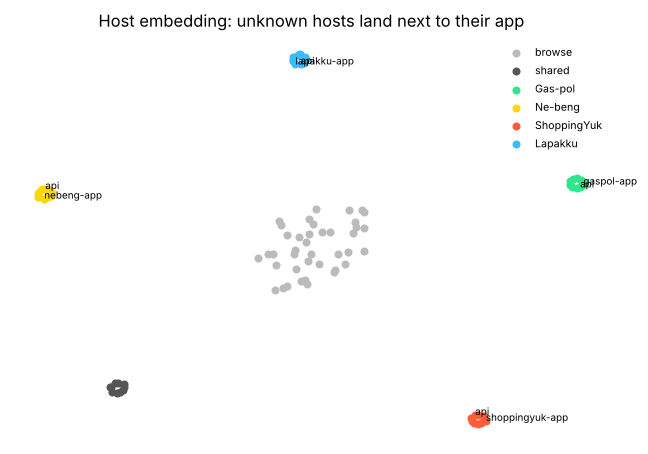

In [5]:
from sklearn.decomposition import PCA
hosts = [h for h in w2v_hosts.wv.index_to_key]
from sklearn.manifold import TSNE
xy = TSNE(2, perplexity=12, random_state=7, init='pca').fit_transform(w2v_hosts.wv[hosts])
kind = ['shared' if h in z.SHARED else 'browse' if h in z.BROWSE else emb.get(h, '?') for h in hosts]
known = {h for c in catalog.values() for h in c['known']}
fig, ax = plt.subplots(figsize=(6, 4.2))
for k in ['browse', 'shared'] + list(BRANDS):
    sel = np.array(kind) == k
    c = np.array(BRANDS[k]['color']) / 255 if k in BRANDS else ('#bbb' if k == 'browse' else '#555')
    ax.scatter(*xy[sel].T, s=18, color=c, label=BRANDS[k]['name'] if k in BRANDS else k)
for i, h in enumerate(hosts):
    if h in known: ax.annotate(h.split('.')[0] if h.startswith('api') else h.split('.')[0], xy[i], fontsize=6.5)
ax.set_axis_off(); ax.legend(frameon=False, fontsize=7, loc='best'); ax.set_title('Host embedding: unknown hosts land next to their app')
plt.tight_layout(); plt.savefig('../docs/host-embedding.png'); plt.show()

## 2. Labelled panel
Models are trained on a 10% **panel** of people whose app receipts are known (in production: a consented research panel). Everything is then scored on the other 90%.

## 3. Drivers vs customers
Per person and brand: sessions, distinct cells, active hours, share of partner-endpoint traffic, distance moved.

In [6]:
users = m.user_features(sessions)
panel = m.split_panel(users)
users['driver_pred'], driver_rep = m.fit_driver(users, panel)
s = sessions.merge(users[['person', 'brand', 'driver_pred']], on=['person', 'brand'])
ride_users = users[users.brand.isin(['gaspol', 'nebeng'])]
print(f"driver precision {driver_rep['precision']:.2f} · recall {driver_rep['recall']:.2f}")
print(f"drivers as share of ride-hailing app users: {ride_users.driver_pred.mean():.1%}")

driver precision 0.94 · recall 0.89
drivers as share of ride-hailing app users: 7.0%


## 4. Which service?
A session's host hint is wrong or ambiguous 22% of the time, so the model also uses bytes, duration and movement afterwards (a Ride moves you; Food doesn't).

In [7]:
cust = s[~s.driver_pred].reset_index(drop=True)
cpanel = m.split_panel(cust)
cust['service_pred'], svc_rep = m.fit_service(cust, cpanel)
for k, r in svc_rep.items():
    print(f"{k:13s} accuracy {r['accuracy']:.2f} · " + ' · '.join(f"{c} F1 {r[c]['f1-score']:.2f}" for c in r if c not in ('accuracy', 'macro avg', 'weighted avg')))

e-commerce    accuracy 0.86 · Electronics F1 0.84 · Fashion F1 0.88 · Groceries F1 0.87 · Home F1 0.83
ride-hailing  accuracy 0.93 · Driver F1 0.66 · Food F1 0.92 · Mart F1 0.85 · Transport F1 0.96


## 4b. Ride or Car, when both use one host
Two-wheel **Ride** and four-wheel **Car** usually call the same host, so the model above can only say **Transport**.
The way in: **Ne-beng** calls a separate host for its car product. That gives free labels on Ne-beng's own traffic.
A supervised model learns what a car trip looks like on the network (longer, slower in traffic, more toll-road cells,
more stop-and-go) and then labels **Gas-pol**, whose host says nothing.

In [8]:
cust['service_pred'], rc_rep = m.split_ride_car(cust, teacher='nebeng', student='gaspol')
print(f"Gas-pol ordered trips labelled correctly: {rc_rep['accuracy_ordered']:.0%} (all transport sessions: {rc_rep['accuracy_all']:.0%})")
print(f"Gas-pol car share of trips: true {rc_rep['car_share_true']:.0%} · estimated {rc_rep['car_share_pred']:.0%}")
print(f"teacher label noise (car sessions that missed their own host): {rc_rep['teacher_label_noise']:.0%}")

Gas-pol ordered trips labelled correctly: 94% (all transport sessions: 77%)
Gas-pol car share of trips: true 28% · estimated 23%
teacher label noise (car sessions that missed their own host): 7%


Trips are easy; sessions that end without a trip are mostly guesswork, which is why the session-level number is lower. The car share comes out a little low because some Ne-beng car sessions miss their own host and teach the model they were rides. In production that bias is measured on a panel and corrected.

## 5. Did the session end in an order?
The threshold is set so the predicted transaction rate matches the panel's rate. That keeps the market totals unbiased even though single sessions are uncertain.

In [9]:
cust['txn_pred'], txn_rep = m.fit_txn(cust, cpanel)
print(f"AUC {txn_rep['auc']:.3f} · precision {txn_rep['precision']:.2f} · recall {txn_rep['recall']:.2f}")
print(f"sessions with an order: true {txn_rep['true_rate']:.1%} · predicted {txn_rep['pred_rate']:.1%}")
dau = cust.groupby(['person', 'brand']).txn_pred.any()
print(f"customers who ordered at least once today: {dau.mean():.1%}")

AUC 0.964 · precision 0.79 · recall 0.78
sessions with an order: true 12.0% · predicted 11.8%
customers who ordered at least once today: 23.0%


## 6. The funnel

In [10]:
rows = []
for b, cfg in BRANDS.items():
    u = users[users.brand == b]; c = cust[cust.brand == b]
    rows.append(dict(brand=cfg['name'], app_dau=len(u) * SCALE, drivers=u.driver_pred.sum() * SCALE,
                     customers=(~u.driver_pred).sum() * SCALE,
                     ordering_customers=c[c.txn_pred].person.nunique() * SCALE))
funnel = pd.DataFrame(rows).set_index('brand')
print(f'telco DAU (Jabodetabek, simulated): {len(people) * SCALE / 1e6:.0f}M')
(funnel / 1e6).round(2).rename(columns=lambda x: x + ' (M)')

telco DAU (Jabodetabek, simulated): 30M


,app_dau (M),drivers (M),customers (M),ordering_customers (M)
brand,,,,
Gas-pol,5.26,0.36,4.90,1.27
Ne-beng,4.14,0.31,3.83,0.98
ShoppingYuk,4.74,0.00,4.74,0.94
Lapakku,3.13,0.00,3.13,0.63


## 7. The question clients pay for
Food: daily users who ordered, by area, Gas-pol vs Ne-beng.

,Gas-pol (K),Ne-beng (K),lime_share
area,,,
BSD & Tangerang Selatan,32,48,60%
Tangerang,30,28,48%
Jakarta Utara,16,14,47%
Jakarta Barat,41,33,45%
Bekasi,50,39,44%
Cikarang,30,22,43%
Jakarta Timur,51,36,42%
Jakarta Selatan,58,40,41%
Depok,46,32,41%


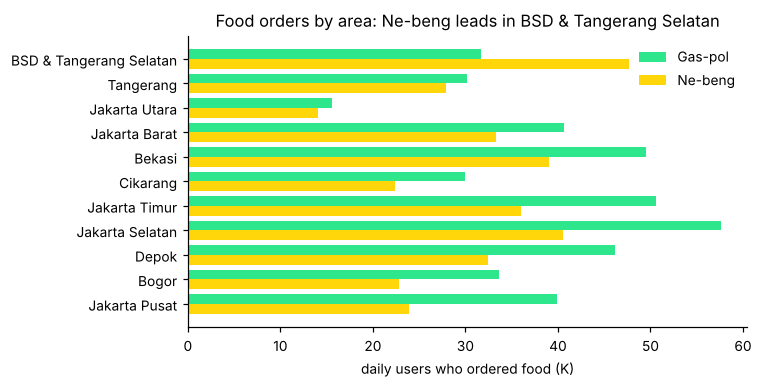

In [11]:
cust['area'] = cells.area.values[cust.cell]
food = cust[(cust.service_pred == 'Food') & cust.txn_pred & cust.brand.isin(['gaspol', 'nebeng'])]
tab = food.groupby(['area', 'brand']).person.nunique().unstack().mul(SCALE)
tab['lime_share'] = tab.nebeng / (tab.gaspol + tab.nebeng)
tab = tab.sort_values('lime_share', ascending=False)
display((tab[['gaspol', 'nebeng']] / 1e3).round(0).astype(int).rename(columns={'gaspol': 'Gas-pol (K)', 'nebeng': 'Ne-beng (K)'}).join(tab.lime_share.map('{:.0%}'.format)))

fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(tab))
ax.barh(y - .2, tab.gaspol / 1e3, .4, color=np.array(BRANDS['gaspol']['color']) / 255, label='Gas-pol')
ax.barh(y + .2, tab.nebeng / 1e3, .4, color=np.array(BRANDS['nebeng']['color']) / 255, label='Ne-beng')
ax.set_yticks(y, tab.index); ax.invert_yaxis(); ax.set_xlabel('daily users who ordered food (K)')
ax.legend(frameon=False); ax.set_title('Food orders by area: Ne-beng leads in BSD & Tangerang Selatan')
plt.tight_layout(); plt.savefig('../docs/food-by-area.png'); plt.show()

## 8. Export for the 3D map

In [12]:
s2 = s.merge(cust[['person', 'brand', 'hour', 'cell', 'service_pred', 'txn_pred']].drop_duplicates(['person', 'brand', 'hour', 'cell']),
              on=['person', 'brand', 'hour', 'cell'], how='left')
s2['service_pred'] = s2.service_pred.fillna('Driver'); s2['txn_pred'] = s2.txn_pred.fillna(False).astype(bool)
brands = {b: dict(name=c['name'], kind=c['kind'], color=c['color']) for b, c in BRANDS.items()}
services = {b: list(SERVICES[c['kind']]) for b, c in BRANDS.items()}
svc_hours = {v: np.round(bumps(h), 4).tolist() for v, h in SVC_HOURS.items()}
metrics = dict(driver=driver_rep, txn=txn_rep, ride_car=rc_rep, service={k: round(r['accuracy'], 3) for k, r in svc_rep.items()},
               txn_dau=float(dau.mean()))
trips = {b: m.driver_trips(cells, s2, b, n=220) for b in ('gaspol', 'nebeng')}
# sessionization demo: host map + one person's morning, for the web
from sklearn.manifold import TSNE
hx = TSNE(2, perplexity=12, random_state=7, init='pca').fit_transform(w2v_hosts.wv[hosts]); hx = (hx - hx.min(0)) / (hx.max(0) - hx.min(0))
host_map = [[round(float(a), 3), round(float(b), 3), k, int(h in known), h] for (a, b), k, h in zip(hx, kind, hosts)]
pred, app = z.sessionize(events, emb)
events['pred'] = pred; events['app'] = app
g = events[events.true_session >= 0].groupby('person')
span = g.t.max() - g.t.min()
busy = ((g.brand.nunique() * 100 + g.true_session.nunique() * 10) * (span < 4 * 3600)).idxmax()   # several apps and sessions within a few hours
tl = events[events.person == busy]
app_t = tl[tl.true_session >= 0].t
tl = tl[(tl.t >= app_t.min() - 1200) & (tl.t <= app_t.max() + 1200)]
timeline = [[int(t), h, a or ('shared' if h in z.SHARED else 'browse'), int(p)] for t, h, a, p in zip(tl.t, tl.host, tl.app, tl.pred)]
metrics['sessions'] = sess_eval
m.export_web('../web/data/omni.json', cells, people, s2, brands, services, svc_hours, metrics, SCALE, trips,
             extra=dict(host_map=host_map, timeline=timeline))
import os; print(f"{os.path.getsize('../web/data/omni.json') / 1e6:.1f} MB")

1.5 MB


## Takeaways
- Four signals carry most of the weight: the host hint, payment endpoints, bytes/duration, and movement after the session.
- Single sessions are uncertain (precision around 0.8), but calibrated totals per area are what clients buy, and those are stable.
- In production: PySpark over clickstream and cell records, models tracked in MLflow, refreshed daily per city.